# Workshop 2 - Object detection using web camera
## Name : Abinaya A
## Register number : 212224230004

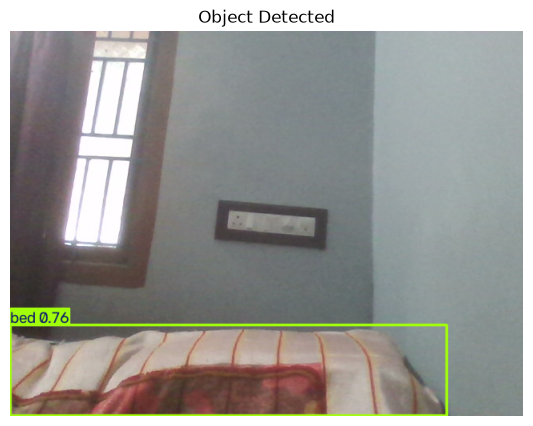

Detected: bed (0.76)
Webcam released.


In [2]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
from IPython.display import clear_output

model = YOLO("yolov8n.pt")

cap = cv2.VideoCapture(0)
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)

if not cap.isOpened():
    print("Error: Could not open webcam.")
else:
    MAX_FRAMES = 300
    frame_count = 0

    try:
        while frame_count < MAX_FRAMES:
            ret, frame = cap.read()
            if not ret:
                print("Failed to capture frame.")
                break

            frame_count += 1
            if frame_count % 2 != 0:
                continue

            results = model(frame, conf=0.5, imgsz=320, verbose=False)

            # Stop as soon as at least one object is detected
            if len(results[0].boxes) > 0:
                annotated = cv2.cvtColor(results[0].plot(), cv2.COLOR_BGR2RGB)

                clear_output(wait=True)
                plt.figure(figsize=(7, 5))
                plt.imshow(annotated)
                plt.title("Object Detected")
                plt.axis("off")
                plt.show()

                # Print what was found
                for box in results[0].boxes:
                    name = model.names[int(box.cls)]
                    print(f"Detected: {name} ({float(box.conf):.2f})")
                break

    except KeyboardInterrupt:
        print("Stopped by user.")

    finally:
        cap.release()
        print("Webcam released.")